# Лабораторная работа № 4.1
## Статистические зависимости

**Выполнили:**

- Левченков Артемий Викторович;
- Бикбулатова Динара Фануровна;
- Ладыгин Максим Александрович.

**Группа:** БИВТ-24-АЭ-3

**Исходные данные:** дискретный ряд распределения возраста людей, совершивших преступления в Москве в 2021 году, из ЛР 1.

**Цель работы:** вычислить коэффициент линейной корреляции между возрастом $X$ и абсолютной частотой $Y$, проверить его значимость при $\alpha=0{,}05$ и построить корреляционное поле.

### 1. Исходные данные

Каждая строка дискретного ряда даёт одну пару $(x_i,y_i)$: возраст и его частоту. $N$ — число людей в исходном файле, $n$ — число пар для корреляции. Частота здесь является значением $Y$, поэтому повторно взвешивать пары по частотам не нужно. Используем тот же ряд, что в ЛР 1, без добавления отсутствующих возрастов.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

data = pd.read_table("data/moscow.txt", header=None)[0]
N = len(data)

discrete = data.value_counts().sort_index().rename_axis("x").reset_index(name="n")
x = discrete["x"]
y = discrete["n"]
n = len(x)

print("Количество людей N =", N)
print("Количество пар n =", n)
print("X — возраст, Y — абсолютная частота возраста")
display(discrete)

Количество людей N = 32423
Количество пар n = 58
X — возраст, Y — абсолютная частота возраста


,x,n
0,14,49
1,15,53
2,16,236
3,17,126
4,18,806
5,19,971
6,20,910
7,21,716
8,22,944
9,23,1071


### 2. Коэффициент линейной корреляции

Средние, ковариация и коэффициент корреляции:

$$\bar x=\frac{\sum_{i=1}^n x_i}{n},\qquad \bar y=\frac{\sum_{i=1}^n y_i}{n},$$
$$m_{xy}=\frac{1}{n}\sum_{i=1}^n(x_i-\bar x)(y_i-\bar y),$$
$$\sigma_x^*=\sqrt{\frac{\sum_{i=1}^n(x_i-\bar x)^2}{n}},\qquad
\sigma_y^*=\sqrt{\frac{\sum_{i=1}^n(y_i-\bar y)^2}{n}},$$
$$r_{xy}=\frac{m_{xy}}{\sigma_x^*\sigma_y^*}
=\frac{\sum_{i=1}^n(x_i-\bar x)(y_i-\bar y)}
{\sqrt{\sum_{i=1}^n(x_i-\bar x)^2}\sqrt{\sum_{i=1}^n(y_i-\bar y)^2}}.$$

Эквивалентная запись:

$$r_{xy}=\frac{\overline{xy}-\bar x\bar y}{\sigma_x^*\sigma_y^*},\qquad
\overline{xy}=\frac{\sum_{i=1}^n x_i y_i}{n}.$$

В ковариации и дисперсиях используется одинаковый делитель $n$.

In [2]:
def linear_correlation(x, y):
    if len(x) != len(y) or len(x) < 3:
        raise ValueError("Нужны два ряда одинаковой длины и не менее трёх пар.")

    x = x.reset_index(drop=True)
    y = y.reset_index(drop=True)
    n = len(x)
    mean_x = sum(x) / n
    mean_y = sum(y) / n
    covariance = sum((x - mean_x) * (y - mean_y)) / n
    sigma_x = (sum((x - mean_x) ** 2) / n) ** 0.5
    sigma_y = (sum((y - mean_y) ** 2) / n) ** 0.5

    if sigma_x == 0 or sigma_y == 0:
        raise ValueError("СКО равно нулю: коэффициент корреляции не определён.")

    r = covariance / (sigma_x * sigma_y)
    r = max(-1, min(1, r))  # учитываем возможную погрешность вычислений у границ
    return mean_x, mean_y, covariance, sigma_x, sigma_y, r


mean_x, mean_y, covariance, sigma_x, sigma_y, r = linear_correlation(x, y)

print(f"Средняя X = {mean_x:.4f}")
print(f"Средняя Y = {mean_y:.4f}")
print(f"Ковариация m_xy = {covariance:.4f}")
print(f"СКО X = {sigma_x:.4f}")
print(f"СКО Y = {sigma_y:.4f}")
print(f"Коэффициент корреляции r_xy = {r:.4f}")

Средняя X = 42.5862
Средняя Y = 559.0172
Ковариация m_xy = -4032.3032
СКО X = 16.8840
СКО Y = 413.4125
Коэффициент корреляции r_xy = -0.5777


### 3. Интерпретация коэффициента

Знак $r$ определяет направление связи, а $|r|$ — её силу:

- $r=0$: линейная корреляция отсутствует;
- $0<|r|\le0{,}3$: слабая;
- $0{,}3<|r|\le0{,}5$: умеренная;
- $0{,}5<|r|\le0{,}7$: заметная;
- $0{,}7<|r|<1$: сильная;
- $|r|=1$: функциональная зависимость.

In [3]:
def correlation_level(r):
    r_abs = abs(r)
    if r_abs == 0:
        return "линейная корреляция отсутствует"
    elif 0 < r_abs <= 0.3:
        return "слабая"
    elif 0.3 < r_abs <= 0.5:
        return "умеренная"
    elif 0.5 < r_abs <= 0.7:
        return "заметная"
    elif 0.7 < r_abs < 1:
        return "сильная"
    elif r_abs == 1:
        return "функциональная зависимость"


if r > 0:
    direction = "прямая"
elif r < 0:
    direction = "обратная"
else:
    direction = "не определяется, так как r = 0"

level = correlation_level(r)
print("Направление связи:", direction)
print("Сила связи:", level)

if r < 0:
    print("В исследуемом ряду большему возрасту в целом соответствует меньшая частота.")
elif r > 0:
    print("В исследуемом ряду большему возрасту в целом соответствует большая частота.")
else:
    print("Линейная корреляция между возрастом и частотой не обнаружена.")

Направление связи: обратная
Сила связи: заметная
В исследуемом ряду большему возрасту в целом соответствует меньшая частота.


### 4. Проверка значимости коэффициента корреляции

Проверяем гипотезы:

$$H_0:\rho_{xy}=0,\qquad H_1:\rho_{xy}\ne0,\qquad \alpha=0{,}05.$$

$\rho_{xy}$ — коэффициент корреляции генеральной совокупности, $r_{xy}$ — рассчитанный по данным коэффициент.

$$t_{\text{набл}}=\frac{r_{xy}\sqrt{n-2}}{\sqrt{1-r_{xy}^2}},\qquad k=n-2.$$

Критическая область двусторонняя:

$$t_{\text{кр}}=t_{1-\alpha/2;k},\qquad |t_{\text{набл}}|\ge t_{\text{кр}}.$$

Если $|t_{\text{набл}}|<t_{\text{кр}}$, нет оснований отвергать $H_0$; иначе $H_0$ отвергается. `t.ppf` находит квантиль распределения Стьюдента.

In [4]:
alpha = 0.05
k = n - 2

if abs(r) == 1:
    t_obs = float("inf") if r > 0 else float("-inf")
    print("При |r| = 1 статистика не конечна; используем её предельное значение.")
else:
    t_obs = r * (n - 2) ** 0.5 / (1 - r ** 2) ** 0.5

t_crit = t.ppf(1 - alpha / 2, k)

print("H₀: ρ_xy = 0; H₁: ρ_xy ≠ 0")
print(f"Уровень значимости α = {alpha}")
print(f"Число пар n = {n}, число степеней свободы k = {k}")
print(f"t наблюдаемое = {t_obs:.4f}")
print(f"|t наблюдаемое| = {abs(t_obs):.4f}")
print(f"t критическое = {t_crit:.4f}")

if abs(t_obs) >= t_crit:
    print("|t_набл| ≥ t_кр: H₀ отвергается.")
    print("По критерию коэффициент корреляции значимо отличается от нуля.")
else:
    print("|t_набл| < t_кр: нет оснований отвергнуть H₀.")
    print("Статистически значимая линейная корреляция не установлена.")

H₀: ρ_xy = 0; H₁: ρ_xy ≠ 0
Уровень значимости α = 0.05
Число пар n = 58, число степеней свободы k = 56
t наблюдаемое = -5.2962
|t наблюдаемое| = 5.2962
t критическое = 2.0032
|t_набл| ≥ t_кр: H₀ отвергается.
По критерию коэффициент корреляции значимо отличается от нуля.


Критерий предполагает независимые наблюдения из двумерной нормальной совокупности. Для пар «возраст — частота» эти условия не установлены, что ограничивает интерпретацию результата. Неотвержение $H_0$ не доказывает, что $\rho_{xy}=0$.

### 5. Корреляционное поле

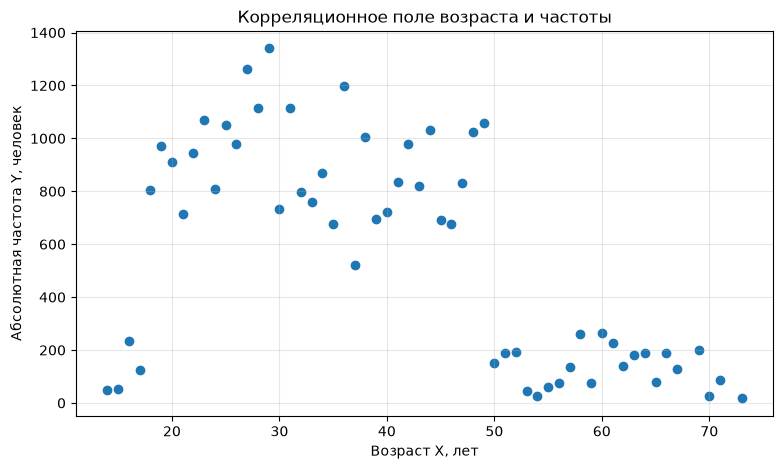

In [5]:
plt.figure(figsize=(9, 5))
plt.scatter(x, y)
plt.title("Корреляционное поле возраста и частоты")
plt.xlabel("Возраст X, лет")
plt.ylabel("Абсолютная частота Y, человек")
plt.grid(alpha=0.3)
plt.show()

### 6. Вывод

In [6]:
print(f"Исследовано {n} пар «возраст — частота».")
print(f"r_xy = {r:.4f}; направление: {direction}; сила связи: {level}.")

if abs(t_obs) >= t_crit:
    print(f"При α = {alpha}: |t_набл| = {abs(t_obs):.4f} ≥ t_кр = {t_crit:.4f}.")
    print("По применённому критерию H₀: ρ_xy = 0 отвергается.")
else:
    print(f"При α = {alpha}: |t_набл| = {abs(t_obs):.4f} < t_кр = {t_crit:.4f}.")
    print("По применённому критерию нет оснований отвергнуть H₀: ρ_xy = 0.")

print("Корреляция не доказывает причинную связь и не оценивает вероятность преступления для человека.")

Исследовано 58 пар «возраст — частота».
r_xy = -0.5777; направление: обратная; сила связи: заметная.
При α = 0.05: |t_набл| = 5.2962 ≥ t_кр = 2.0032.
По применённому критерию H₀: ρ_xy = 0 отвергается.
Корреляция не доказывает причинную связь и не оценивает вероятность преступления для человека.
